# Clase 4c — PER de «hola mundo» en canal plano y selectivo

Partimos de la trama de la clase 4: **8 upchirps + 2¼ downchirps + 10 chirps de payload** (`hola mundo`, un byte por chirp). El receptor busca el inicio por correlación normalizada con la **cabecera completa** y luego demodula los diez bytes con dechirp y FFT.

Comparamos dos canales de la clase 3, ambos con AWGN complejo añadido **después** del canal: plano $h_{\mathrm{plano}}=[1]$ y selectivo $h_{\mathrm{sel}}=[\sqrt{0.8},\sqrt{0.2}]$. Un paquete falla si no se detecta, si el inicio estimado no es exacto o si cambia al menos un byte. La figura final muestra la **PER frente a SNR** para ambos canales.

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np

raiz = Path.cwd()
if not (raiz / 'src').exists():
    raiz = raiz.parent
if str(raiz) not in sys.path:
    sys.path.insert(0, str(raiz))

from src.lora_chirp import agregar_ruido_awgn, modular_simbolo, parametros_ruido_desde_snr

## 1. Trama y canales

Usamos $SF=8$, $N=256$ muestras por chirp y $B=125$ kHz. La plantilla de detección incluye el preámbulo y **todos** los downchirps; el payload empieza inmediatamente después. El FIR se aplica a la señal concatenada, incluidos los márgenes de silencio, para conservar la memoria entre chirps. Los taps selectivos tienen energía cuadrática total 1; no representan desvanecimiento aleatorio.

In [2]:
B = 125_000
SF = 8
N = 2**SF
mensaje = 'hola mundo'
payload_transmitido = mensaje.encode('ascii')
assert len(payload_transmitido) == 10
k = np.arange(N)
upchirp_cero = modular_simbolo(0, k, N)
downchirp_cero = np.conj(upchirp_cero)
preambulo = np.tile(upchirp_cero, 8)
sincronizacion = np.r_[downchirp_cero, downchirp_cero, downchirp_cero[:N // 4]]
cabecera_conocida = np.r_[preambulo, sincronizacion]
payload_modulado = np.concatenate([modular_simbolo(valor, k, N) for valor in payload_transmitido])
trama_transmitida = np.r_[cabecera_conocida, payload_modulado]
longitud_trama = len(trama_transmitida)
longitud_payload = len(payload_modulado)
potencia_trama = float(np.mean(np.abs(trama_transmitida)**2))
canales = {
    'Plano': np.array([1.0]),
    'Selectivo (2 taps)': np.array([np.sqrt(0.8), np.sqrt(0.2)]),
}
assert longitud_trama == 5184 and len(cabecera_conocida) == 2624
assert all(np.isclose(np.sum(np.abs(h)**2), 1) for h in canales.values())
print(f'{mensaje!r}: {len(payload_transmitido)} bytes | trama: {longitud_trama} muestras '
      f'({longitud_trama / B * 1e3:.3f} ms) | potencia activa: {potencia_trama:.5f}')

'hola mundo': 10 bytes | trama: 5184 muestras (41.472 ms) | potencia activa: 0.00391


## 2. Receptor: correlación temporal y lectura del payload

Para cada inicio candidato $m$ calculamos

$$C[m]=\frac{|\langle c,r[m:m+L]\rangle|^2}{\|c\|^2\,\|r[m:m+L]\|^2},$$

con $c$ igual a la cabecera completa de longitud $L$. Se declara una trama si el máximo supera el umbral manual $0{,}01$, como en la clase 4. La correlación se evalúa con FFT para repetir muchos paquetes; es la misma correlación lineal normalizada. El detector usa la plantilla ideal en ambos canales, sin ecualizar el canal selectivo.

In [3]:
UMBRAL = 0.01
L = len(cabecera_conocida)
LONGITUD_BLOQUE = longitud_trama + 2 * N
N_FFT = 1 << (LONGITUD_BLOQUE + L - 2).bit_length()
espectro_plantilla = np.fft.fft(np.conj(cabecera_conocida[::-1]), n=N_FFT)
energia_plantilla = float(np.vdot(cabecera_conocida, cabecera_conocida).real)


def puntajes_correlacion(bloque):
    if len(bloque) != LONGITUD_BLOQUE:
        raise ValueError('El bloque debe contener la trama y los dos márgenes')
    correlacion = np.fft.ifft(np.fft.fft(bloque, n=N_FFT) * espectro_plantilla)
    coincidencias = correlacion[L - 1:len(bloque)]
    energia_acumulada = np.r_[0.0, np.cumsum(np.abs(bloque)**2)]
    energias_ventana = energia_acumulada[L:] - energia_acumulada[:-L]
    puntajes = np.zeros(len(coincidencias))
    np.divide(np.abs(coincidencias)**2, energia_plantilla * energias_ventana,
              out=puntajes, where=energias_ventana > 0)
    return puntajes


def leer_payload(bloque, inicio):
    if inicio is None:
        return None
    comienzo = inicio + L
    payload = bloque[comienzo:comienzo + longitud_payload]
    if len(payload) != longitud_payload:
        return None
    simbolos = payload.reshape(len(payload_transmitido), N)
    downchirp = np.exp(-1j * 2 * np.pi * k**2 / N)
    espectros = np.fft.fft(simbolos * downchirp, axis=1)
    return bytes(np.argmax(np.abs(espectros)**2, axis=1).tolist())


def detectar_paquete(bloque):
    puntajes = puntajes_correlacion(bloque)
    candidato = int(np.argmax(puntajes))
    inicio = candidato if puntajes[candidato] > UMBRAL else None
    return inicio, leer_payload(bloque, inicio), puntajes


def bloque_por_canal(inicio, h):
    bloque = np.zeros(LONGITUD_BLOQUE, dtype=complex)
    bloque[inicio:inicio + longitud_trama] = trama_transmitida
    return np.convolve(bloque, h)[:LONGITUD_BLOQUE]


# Equivalencia con la correlación directa y control de los dos canales sin ruido.
inicio_control = N + 1
for nombre, h in canales.items():
    limpio = bloque_por_canal(inicio_control, h)
    puntajes = puntajes_correlacion(limpio)
    np.testing.assert_allclose(puntajes,
        np.abs(np.correlate(limpio, cabecera_conocida, mode='valid'))**2 /
        (energia_plantilla * np.maximum(
            np.r_[0.0, np.cumsum(np.abs(limpio)**2)][L:] -
            np.r_[0.0, np.cumsum(np.abs(limpio)**2)][:-L], 1e-14)),
        atol=1e-11, rtol=1e-11)
    inicio, dato, _ = detectar_paquete(limpio)
    assert inicio == inicio_control and dato == payload_transmitido, nombre
    print(f'{nombre}: inicio sin ruido = {inicio}, payload = {dato.decode("ascii")!r}')

Plano: inicio sin ruido = 257, payload = 'hola mundo'
Selectivo (2 taps): inicio sin ruido = 257, payload = 'hola mundo'


## 3. Una realización con ruido

Para una misma SNR usamos el mismo ruido complejo en los dos canales. La línea vertical marca el inicio verdadero; la curva muestra cómo cambia el pico de correlación por el FIR y el ruido. La SNR se calcula con la potencia de la **trama transmitida activa**, sin incluir los márgenes de ceros, y conserva la misma potencia de ruido en ambos canales.

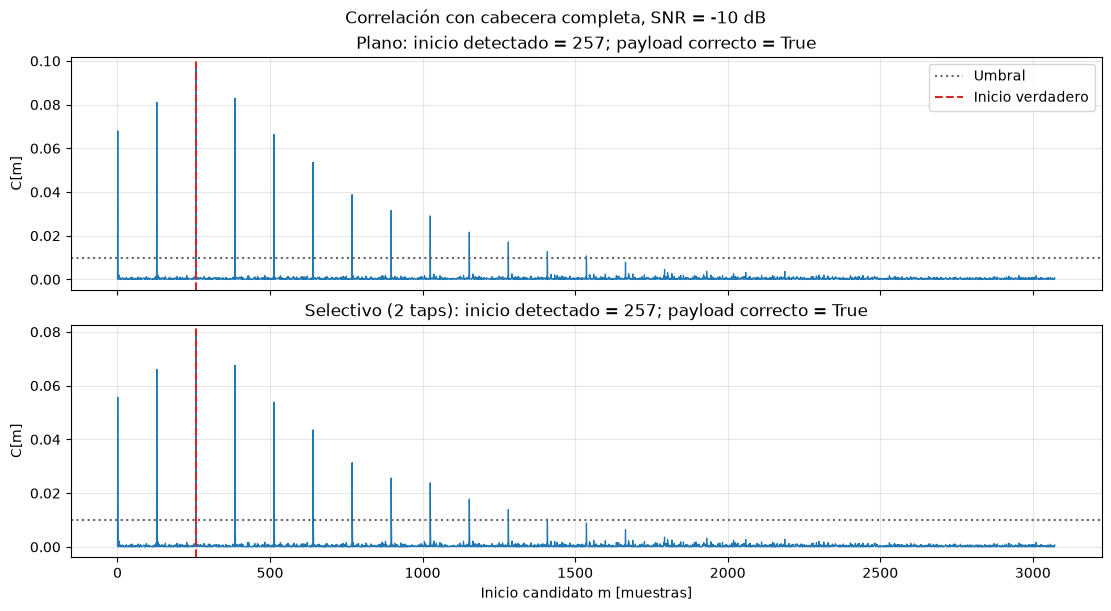

In [4]:
snr_ejemplo_db = -10
generador_ejemplo = np.random.default_rng(2026)
inicio_ejemplo = N + 1
_, sigma_ejemplo = parametros_ruido_desde_snr(snr_ejemplo_db, potencia_trama)
_, ruido_ejemplo = agregar_ruido_awgn(np.zeros(LONGITUD_BLOQUE), sigma_ejemplo,
                                       generador_ejemplo)
fig, axes = plt.subplots(2, 1, figsize=(11, 6), sharex=True, constrained_layout=True)
for ax, (nombre, h) in zip(axes, canales.items()):
    recibido = bloque_por_canal(inicio_ejemplo, h) + ruido_ejemplo
    inicio, dato, puntajes = detectar_paquete(recibido)
    ax.plot(puntajes, lw=0.9)
    ax.axhline(UMBRAL, color='0.4', ls=':', label='Umbral')
    ax.axvline(inicio_ejemplo, color='tab:red', ls='--', label='Inicio verdadero')
    ax.set(ylabel='C[m]', title=f'{nombre}: inicio detectado = {inicio}; '
           f'payload correcto = {dato == payload_transmitido}')
    ax.grid(True, alpha=0.3)
axes[0].legend()
axes[-1].set_xlabel('Inicio candidato m [muestras]')
fig.suptitle(f'Correlación con cabecera completa, SNR = {snr_ejemplo_db} dB')
plt.show()

## 4. PER Monte Carlo frente a SNR

Cada ensayo envía `hola mundo` en un inicio aleatorio impar dentro de un bloque con $2N$ muestras adicionales. Después del canal sumamos AWGN. Para comparar ambos canales, cada par de ensayos comparte **el mismo inicio y la misma realización de ruido**.

Los errores se clasifican una sola vez: **no detectado**, **inicio incorrecto** o **payload incorrecto**. Un paquete sólo es correcto si se detecta, se ubica la primera muestra exacta y se recuperan los 10 bytes. Así,

$$\mathrm{PER}=\frac{N_{\mathrm{no\ detectados}}+N_{\mathrm{inicio\ incorrecto}}+N_{\mathrm{payload\ incorrecto}}}{K}.$$

El umbral es el mismo valor manual de la clase 4; no implica igual tasa de falsa alarma en los dos canales. Las falsas alarmas en bloques vacíos no entran en esta PER.

In [13]:
snrs_db = np.array([-16, -14, -12, -10, -9, -8, -7, -6, -5, -3])
paquetes_por_snr = 50_000  # subir a 10_000 o 50_000 para resolver PER más pequeñas
semilla_per = 2027
generador_per = np.random.default_rng(semilla_per)
conteos_causas = {nombre: [] for nombre in canales}
resultados_per = {nombre: [] for nombre in canales}

print('SNR [dB]  Canal                 No detecta  Inicio mal  Payload mal   Errores/K       PER')
for snr_db in snrs_db:
    _, sigma = parametros_ruido_desde_snr(snr_db, potencia_trama)
    conteos = {nombre: np.zeros(3, dtype=int) for nombre in canales}
    for _ in range(paquetes_por_snr):
        inicio_real = int(2 * generador_per.integers(0, N) + 1)
        _, ruido = agregar_ruido_awgn(np.zeros(LONGITUD_BLOQUE), sigma, generador_per)
        for nombre, h in canales.items():
            if(snr_db>=-8 and nombre=='Plano'):
                continue
            recibido = bloque_por_canal(inicio_real, h) + ruido
            inicio_estimado, dato_estimado, _ = detectar_paquete(recibido)
            if inicio_estimado is None:
                conteos[nombre][0] += 1
            elif inicio_estimado != inicio_real:
                conteos[nombre][1] += 1
            elif dato_estimado != payload_transmitido:
                conteos[nombre][2] += 1
    for nombre in canales:
        errores = int(conteos[nombre].sum())
        per = errores / paquetes_por_snr
        conteos_causas[nombre].append(conteos[nombre].copy())
        resultados_per[nombre].append(per)
        print(f'{snr_db:8.0f}  {nombre:<21} {conteos[nombre][0]:10d} '
              f'{conteos[nombre][1]:11d} {conteos[nombre][2]:12d} '
              f'{errores:6d}/{paquetes_por_snr:<5d} {per:9.2e}')

resultados_per = {nombre: np.asarray(valores) for nombre, valores in resultados_per.items()}
conteos_causas = {nombre: np.asarray(valores) for nombre, valores in conteos_causas.items()}
for nombre in canales:
    np.testing.assert_allclose(conteos_causas[nombre].sum(axis=1) / paquetes_por_snr,
                               resultados_per[nombre])

SNR [dB]  Canal                 No detecta  Inicio mal  Payload mal   Errores/K       PER
     -16  Plano                          0         704        49020  49724/50000  9.94e-01
     -16  Selectivo (2 taps)            54        1432        48499  49985/50000  1.00e+00
     -14  Plano                          0         102        38580  38682/50000  7.74e-01
     -14  Selectivo (2 taps)             0         256        47782  48038/50000  9.61e-01
     -12  Plano                          0           5         7340   7345/50000  1.47e-01
     -12  Selectivo (2 taps)             0          27        27378  27405/50000  5.48e-01
     -10  Plano                          0           0          128    128/50000  2.56e-03
     -10  Selectivo (2 taps)             0           2         6627   6629/50000  1.33e-01
      -9  Plano                          0           0            6      6/50000  1.20e-04
      -9  Selectivo (2 taps)             0           0         2966   2966/50000  5.93e-02


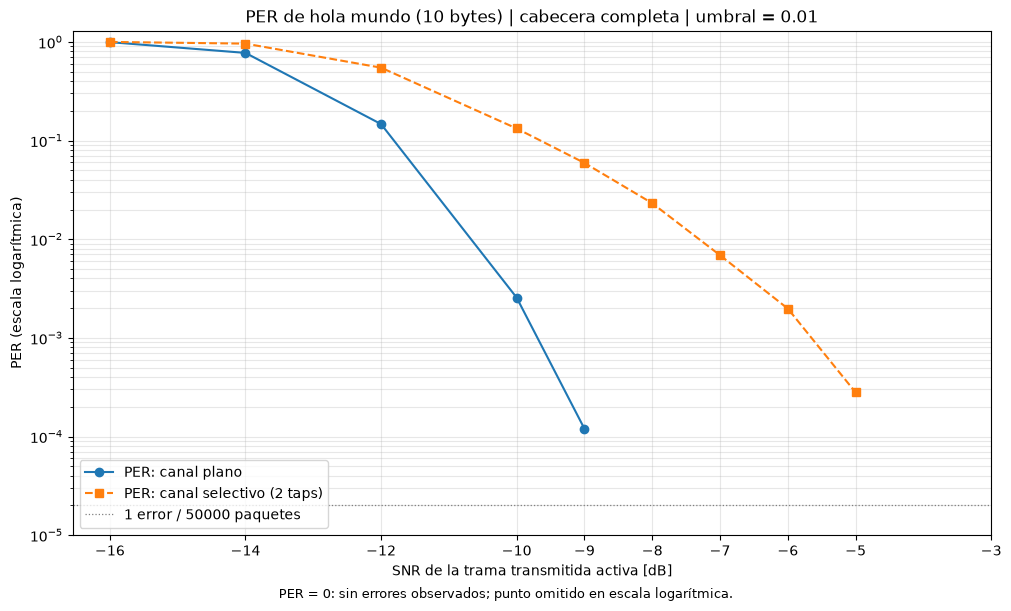

In [14]:
fig, ax = plt.subplots(figsize=(10, 6), constrained_layout=True)
for (nombre, per), estilo in zip(resultados_per.items(), ('o-', 's--')):
    ax.semilogy(snrs_db, np.where(per > 0, per, np.nan), estilo,
                lw=1.5, label=f'PER: canal {nombre.lower()}')
ax.axhline(1 / paquetes_por_snr, color='0.5', ls=':', lw=0.9,
           label=f'1 error / {paquetes_por_snr} paquetes')
ax.set(xlabel='SNR de la trama transmitida activa [dB]',
       ylabel='PER (escala logarítmica)',
       title=f'PER de hola mundo (10 bytes) | cabecera completa | umbral = {UMBRAL}',
       ylim=(0.5 / paquetes_por_snr, 1.3))
ax.set_xticks(snrs_db)
ax.grid(True, which='both', alpha=0.3)
ax.legend(loc='lower left')
fig.supxlabel('PER = 0: sin errores observados; punto omitido en escala logarítmica.', fontsize=9)
plt.show()

**Lectura de la figura.** Cada punto es la fracción de paquetes completos fallidos. La tabla conserva los valores cero que no se pueden dibujar en escala logarítmica y separa sus causas. La resolución Monte Carlo es $1/K$; un cero significa que no se observó ningún fallo en esos $K$ ensayos. El canal selectivo es un FIR fijo de dos taps; esta comparación no incluye ecualización, desvanecimiento aleatorio ni CRC.